# CascadeGuard AI: Early Warning for Payment-Service Failures
**IBM Z Datathon project | Python + Jupyter on IBM LinuxONE**

CascadeGuard AI watches live service metrics, detects that a service is starting to fail, ranks which service is the likely source, and traces which dependent services are at risk. It then produces an explainable alert for a human operator.

**Data:** RCAEval, real fault-injection experiments on the Online Boutique microservice system (125 cases, 5 fault types: `cpu`, `mem`, `disk`, `delay`, `loss`). Each case has a known root-cause service and injection time, so every result can be checked against ground truth.

**Pipeline in this notebook**

| Step | Section |
|---|---|
| Get the data | 1 |
| Environment check and settings | 2, 3 |
| Load cases and check the schema | 4, 5 |
| Build features and training labels | 6 |
| Train the detection models | 7 |
| Compare against conventional monitoring | 8 |
| Check the dependency-impact estimate | 9 |
| Alert card and streaming replay | 10 |
| Charts for the presentation | 11 |

## 1. Download the dataset (run once)
Downloads `RE1-OB.zip` from Zenodo, the RCAEval benchmark for the Online Boutique shop (a demo e-commerce app that includes checkout and payment services), and extracts it to `data/RE1`.

- Needs internet access from the Jupyter server.
- After the first successful run, you can comment this cell out so it does not download again.

In [24]:
import urllib.request, zipfile

url = "https://zenodo.org/records/14590730/files/RE1-OB.zip?download=1"
urllib.request.urlretrieve(url, "RE1-OB.zip")
zipfile.ZipFile("RE1-OB.zip").extractall("data/RE1")


## 2. Imports and environment check
Loads the libraries used in the notebook: `pandas` and `numpy` for data, `scikit-learn` for the two models, and `matplotlib` for charts.

The last line prints the Python, pandas and scikit-learn versions and the CPU architecture. **`arch s390x` confirms the notebook is running on IBM Z / LinuxONE.** Keep this output as evidence for the presentation.

In [29]:
import re, json, time, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest, GradientBoostingClassifier
from sklearn.metrics import precision_recall_fscore_support
warnings.filterwarnings("ignore")
import sklearn, platform
print("python", platform.python_version(), "| pandas", pd.__version__, "| sklearn", sklearn.__version__, "| arch", platform.machine())

python 3.12.15 | pandas 3.0.6 | sklearn 1.9.0 | arch s390x


## 3. Settings and the Online Boutique call graph
**Settings**

| Setting | Meaning |
|---|---|
| `BIN = 5` | Metrics are grouped into 5-second batches, like a live stream |
| `BASE_MAX = 180` | Up to 180 s of healthy data at the start of each case is the baseline |
| `LABEL_LAG = 10` | A service counts as an active incident 10 s after fault injection |
| `THR, CONSEC = 0.6, 3` | CascadeGuard alerts when risk is at least 0.6 for 3 consecutive batches (15 s) |
| `NSIGMA_THR`, `SLO_MULT` | Thresholds for the two conventional baselines |
| `TEST_FROM_INSTANCE = 3` | Repetitions 1 to 3 are used for training, 4 and 5 for testing |

**Call graph.** `CALLS` records which service calls which. `IMPACTED[s]` lists every service that directly or indirectly depends on `s`, so a failing service is traced up to the callers it can hurt. For example, if `paymentservice` fails, `checkoutservice` and `frontend` are affected. The output prints a few of these lists.

In [42]:
DATA_DIR = "data"
PATH_FILTER = r"(re\d|torai)ob"      
BIN = 5                             
BASE_MAX = 180                      
LABEL_LAG = 10                      
THR, CONSEC = 0.6, 3                
NSIGMA_THR, SLO_MULT = 6.0, 2.0      
TEST_FROM_INSTANCE = 3               
SEED = 42

CALLS = {
    "frontend": ["adservice", "cartservice", "checkoutservice", "currencyservice",
                 "productcatalogservice", "recommendationservice", "shippingservice"],
    "checkoutservice": ["cartservice", "currencyservice", "emailservice", "paymentservice",
                        "productcatalogservice", "shippingservice"],
    "recommendationservice": ["productcatalogservice"],
    "cartservice": ["redis"],
}
SERVICES = sorted(set(CALLS) | {c for v in CALLS.values() for c in v})
CALLEES = {s: CALLS.get(s, []) for s in SERVICES}
def _callers(s, seen=None):
    seen = seen if seen is not None else set()
    for a, v in CALLS.items():
        if s in v and a not in seen:
            seen.add(a); _callers(a, seen)
    return seen
IMPACTED = {s: sorted(_callers(s)) for s in SERVICES}   
KINDS = ["cpu", "mem", "diskio", "socket", "workload", "error", "lat"]
RES_KINDS = ["cpu", "mem", "diskio", "socket"]
PAYMENT_PATH = {"paymentservice", "checkoutservice"}
print({s: IMPACTED[s] for s in ["paymentservice", "cartservice", "redis"]})

{'paymentservice': ['checkoutservice', 'frontend'], 'cartservice': ['checkoutservice', 'frontend'], 'redis': ['cartservice', 'checkoutservice', 'frontend']}


## 4. Data loader
Defines the functions that find and read the cases.

- `read_metrics` reads `metrics.json` or `data.csv` first and Parquet last, because `pyarrow` cannot be installed on IBM Z.
- `read_inject` reads each case's fault-injection time.
- `find_cases` finds usable cases under `data/` and keeps only Online Boutique ones.

**Output:** 125 Parquet-only copies were skipped (they cannot be read on this machine) and 125 usable cases remain.

In [41]:
def read_json_metrics(path):
    raw = {k: v for k, v in json.load(open(path)).items() if v}
    union = sorted({p[0] for v in raw.values() for p in v}); pos = {t: i for i, t in enumerate(union)}
    cols = list(raw); arr = np.full((len(union), len(cols)), np.nan)
    for j, k in enumerate(cols):
        for ts, val in raw[k]:
            if val is not None: arr[pos[ts], j] = val
    df = pd.DataFrame(arr, columns=cols); df.insert(0, "time", np.asarray(union, dtype=np.int64))
    return df

def read_metrics(d):
    
    for name in ["metrics.json", "data.csv", "simple_data.csv", "metrics.parquet"]:
        p = d / name
        if p.exists():
            if name.endswith(".json"): return read_json_metrics(p)
            if name.endswith(".csv"): return pd.read_csv(p)
            try:
                return pd.read_parquet(p)
            except ImportError:
                raise ImportError("This case is Parquet-only and pyarrow is not installed. "
                                  "Use the Zenodo (json/csv) download, or convert to CSV elsewhere.")
    raise FileNotFoundError(d)

_cases_idx = None
def read_inject(d, root):
    global _cases_idx
    p = d / "inject_time.txt"
    if p.exists():
        return int(float(p.read_text().split()[0]))
    if _cases_idx is None:
        cp = Path(root) / "cases.parquet"
        _cases_idx = pd.read_parquet(cp) if cp.exists() else pd.DataFrame()
    icol = [c for c in _cases_idx.columns if "inject" in c.lower()]
    if len(_cases_idx) and icol and "case" in _cases_idx:
        m = _cases_idx[_cases_idx.case == d.name]
        if len(m): return int(float(m.iloc[0][icol[0]]))
    raise FileNotFoundError(f"no injection time for {d}")

def _has_parquet():
    for m in ("pyarrow", "fastparquet"):
        try:
            __import__(m); return True
        except ImportError:
            pass
    return False
HAS_PARQUET = _has_parquet()

def find_cases(root):
    usable, parquet_only = set(), set()
    for pat in ["metrics.json", "data.csv", "simple_data.csv"]:
        usable |= {p.parent for p in Path(root).rglob(pat)}
    for p in Path(root).rglob("metrics.parquet"):
        if p.parent not in usable: (usable if HAS_PARQUET else parquet_only).add(p.parent)
    keep = lambda dirs: sorted(d for d in dirs if re.search(PATH_FILTER, str(d).lower().replace("-", "")))
    if parquet_only:
        print(f"Skipping {len(keep(parquet_only))} Parquet-only cases (no pyarrow on this machine).")
    return keep(usable)

case_dirs = find_cases(DATA_DIR)
print(len(case_dirs), "usable Online Boutique cases under", DATA_DIR)
if not case_dirs:
    raise SystemExit("No usable cases. Need metrics.json or data.csv per case (see the first cell), and check DATA_DIR / PATH_FILTER.")

Skipping 125 Parquet-only cases (no pyarrow on this machine).
125 usable Online Boutique cases under data


## 5. Schema check
Column names differ between cases, so this cell counts how many metric columns the loader recognises in about 25 sampled cases.

- **Why it matters:** a metric the loader does not recognise is treated as zero in the features, with no error message.
- **Our run:** between 23 and 45 columns were recognised (median 43). The unrecognised names include node-level columns that are ignored on purpose, plus some `latency` and `load` columns that use different names from the ones the code expects.
- **Takeaway:** a few cases have fewer usable metrics, which is a known limitation to mention.

In [32]:
from collections import Counter
unk, ok_counts = Counter(), []
for d in case_dirs[::max(1, len(case_dirs) // 25)]:
    cols = [c for c in read_metrics(d).columns if c != "time" and not str(c).startswith("time.")]
    ok = 0
    for c in cols:
        sv, k = c.rsplit("_", 1) if "_" in c else (c, "")
        k = "lat" if k == "latency-90" else k
        if sv in SERVICES and k in KINDS: ok += 1
        else: unk[c.rsplit("_", 1)[-1] if "_" in c else c] += 1
    ok_counts.append(ok)
print("recognised metric columns per sampled case: min/median/max =", min(ok_counts), int(np.median(ok_counts)), max(ok_counts))
print("most common unrecognised column suffixes:", unk.most_common(10))
print("example columns:", list(read_metrics(case_dirs[0]).columns[:12]))

recognised metric columns per sampled case: min/median/max = 23 43 45
most common unrecognised column suffixes: [('latency-50', 150), ('load', 120), ('latency', 100), ('error', 31), ('cpu', 25), ('mem', 25), ('workload', 15)]
example columns: ['time', 'adservice_cpu', 'cartservice_cpu', 'checkoutservice_cpu', 'currencyservice_cpu', 'emailservice_cpu', 'frontend_cpu', 'main_cpu', 'paymentservice_cpu', 'productcatalogservice_cpu', 'recommendationservice_cpu', 'redis_cpu']


## 6. Feature engineering and loading the cases
Turns each raw case into rows of features, one row per service per 5-second batch.

1. **Case details.** The service, fault type and repetition number come from the folder name, and the injection time from `inject_time.txt`.
2. **Batching.** Per-second metrics are averaged into 5 s batches.
3. **Healthy baseline.** The start of each case, before the fault, gives each metric's normal level and normal variation.
4. **Z-scores.** Each metric is expressed as "how many standard deviations from normal". A floor on the variation stops tiny natural wobble from producing huge scores, and values are capped at plus or minus 30.
5. **Smoothing.** A 3-batch rolling average looks backward only, so no future data is used.
6. **Dependency features.** Each service is compared with the services it calls. A service that is abnormal while its callees are healthy is a likely source, while one that is abnormal because of a callee is probably a victim.
7. **Label.** `y = 1` for the true root-cause service from 10 s after injection.
8. **Split.** Repetitions 1 to 3 train the models and repetitions 4 and 5 test them, so test cases are runs the models have never seen.

**Output:** 125 cases loaded (75 train, 50 test), a table showing 5 faults across 5 root-cause services with 5 repetitions each.

In [35]:

def case_features(df, inject):
    df = df.copy()
    df = df.drop(
        columns=[c for c in df if str(c).startswith("time.")],
        errors="ignore"
    )
    df = df.drop_duplicates("time").sort_values("time").reset_index(drop=True)
    df = df.replace([np.inf, -np.inf], np.nan).ffill().fillna(0)

    cols = {}
    for c in df.columns:
        if c == "time" or "_" not in str(c):
            continue

        s, k = str(c).rsplit("_", 1)
        k = "lat" if k == "latency-90" else k

        if s in SERVICES and k in KINDS:
            cols[(s, k)] = c

    if df.empty or "time" not in df.columns:
        return None

    t0 = df.time.iloc[0]
    b = ((df.time - t0) // BIN).astype(int)
    grouped = df.groupby(b)

    agg = grouped.mean(numeric_only=True)
    t_end = grouped.time.max()

    base_sec = min(BASE_MAX, 0.6 * (inject - t0))
    base = ((t_end - t0) < base_sec).values

    if base.sum() < 6:
        return None

    Z = {}
    for (s, k), c in cols.items():
        x = agg[c]
        mu = x[base].mean()
        sd = x[base].std()

        z = ((x - mu) / max(sd, 0.1 * abs(mu), 1e-6)).clip(-30, 30)
        Z[(s, k)] = z.rolling(3, min_periods=1).mean()

    zero = pd.Series(0.0, index=agg.index)

    def zf(service, kind):
        return Z.get((service, kind), zero)

    res = {
        s: pd.concat(
            [zf(s, k).abs() for k in RES_KINDS], axis=1
        ).max(axis=1)
        for s in SERVICES
    }

    fe = cols.get(("frontend", "lat"))

    if fe:
        fe_ratio = (
            agg[fe].rolling(3, min_periods=1).mean()
            / max(agg[fe][base].mean(), 1e-6)
        ).clip(upper=50)
    else:
        fe_ratio = zero + 1

    out = []

    for s in SERVICES:
        f = pd.DataFrame(
            {"z_" + k: zf(s, k) for k in KINDS}
        )

        f["lat_slope"] = f.z_lat.diff(3).fillna(0)
        f["res_max"] = res[s]

        f["any_max"] = pd.concat(
            [f.res_max, f.z_lat.abs(), f.z_error.abs()],
            axis=1
        ).max(axis=1)

        cal = CALLEES[s]

        f["callee_lat_max"] = (
            pd.concat([zf(c, "lat") for c in cal], axis=1).max(axis=1)
            if cal else 0.0
        )

        f["callee_res_max"] = (
            pd.concat([res[c] for c in cal], axis=1).max(axis=1)
            if cal else 0.0
        )

        f["lat_delta"] = f.z_lat - f.callee_lat_max
        f["res_delta"] = f.res_max - f.callee_res_max
        f["fe_lat_ratio"] = fe_ratio

        f["service"] = s
        f["t_end"] = t_end.values

        out.append(f)

    result = pd.concat(out, ignore_index=True)
    result = result[result.t_end >= t0 + base_sec].reset_index(drop=True)

    return result, t0 + base_sec



FAULT_NAMES = {
    "cpu", "mem", "memory", "disk", "diskio",
    "delay", "loss", "socket", "network"
}

def infer_case_metadata(d):
   
    tokens = []
    for part in d.parts:
        tokens.extend(part.lower().replace("-", "_").split("_"))

    service = next((s for s in SERVICES if s.lower() in tokens), None)
    fault = next((f for f in tokens if f in FAULT_NAMES), None)

   
    inst = None
    for part in reversed(d.parts):
        if part.isdigit():
            inst = int(part)
            break

   
    if inst is None:
        for part in reversed(d.parts):
            match = re.search(r"(?:^|_)(\d+)$", part.lower())
            if match:
                inst = int(match.group(1))
                break

    if service is None or fault is None or inst is None:
        raise ValueError(
            f"Cannot infer metadata from path: {d}. "
            f"service={service}, fault={fault}, instance={inst}"
        )

    if fault == "memory":
        fault = "mem"

    return service, fault, inst


def get_case_injection(d, root):
   
    p = d / "inject_time.txt"
    if p.exists():
        return int(float(p.read_text().split()[0]))

    
    cp = Path(root) / "cases.parquet"
    if not cp.exists():
        raise FileNotFoundError(f"No inject_time.txt or {cp}")

    index = pd.read_parquet(cp)

    inject_cols = [
        c for c in index.columns if "inject" in c.lower()
    ]
    if not inject_cols:
        raise ValueError("No injection-time column in cases.parquet")

    if "case" not in index.columns:
        raise ValueError("No 'case' column in cases.parquet")

    candidates = {
        d.name,
        str(d),
        str(d.relative_to(root)) if d.is_relative_to(Path(root)) else str(d)
    }

   
    values = index["case"].astype(str)
    mask = values.isin(candidates)

   
    if not mask.any():
        mask = values.map(
            lambda x: Path(x).name == d.name
        )

    matches = index.loc[mask]

    if len(matches) == 1:
        return int(float(matches.iloc[0][inject_cols[0]]))

    raise ValueError(
        f"Could not uniquely match injection time for {d}. "
        f"Matching rows: {len(matches)}"
    )


# Load cases.
frames, meta, skipped = [], [], 0

for d in case_dirs:
    try:
        service, fault, inst = infer_case_metadata(d)
        inject = get_case_injection(d, DATA_DIR)

        res = case_features(read_metrics(d), inject)

        if res is None:
            skipped += 1
            print("skip", d, "-> insufficient healthy baseline")
            continue

        f, base_end = res

        f["case"] = str(d)
        f["root"] = service
        f["fault"] = fault
        f["inst"] = inst
        f["inject"] = inject

        f["y"] = (
            (f.service == service)
            & (f.t_end >= inject + LABEL_LAG)
        ).astype(int)

        frames.append(f)

        meta.append({
            "case": str(d),
            "service": service,
            "fault": fault,
            "inst": inst,
            "inject": inject
        })

    except Exception as e:
        skipped += 1
        print("SKIPPED:", d, "->", type(e).__name__, str(e))



if not frames:
    raise ValueError(
        "No cases were loaded. Review the SKIPPED messages above. "
        "The dataset folder structure or cases.parquet schema "
        "does not match the assumptions in this loader."
    )

feats = pd.concat(frames, ignore_index=True)
cases = pd.DataFrame(meta)

cases["test"] = cases["inst"] > TEST_FROM_INSTANCE

if cases["test"].all() or not cases["test"].any():
    cases["test"] = np.arange(len(cases)) % 10 >= 7

feats = feats.merge(cases[["case", "test"]], on="case")

print(
    f"{len(cases)} cases loaded ({skipped} skipped) | "
    f"train {(~cases.test).sum()} / test {cases.test.sum()}"
)

print(cases.groupby(["fault", "service"]).size().unstack(fill_value=0))


125 cases loaded (0 skipped) | train 75 / test 50
service  adservice  cartservice  checkoutservice  currencyservice  \
fault                                                               
cpu              5            5                5                5   
delay            5            5                5                5   
disk             5            5                5                5   
loss             5            5                5                5   
mem              5            5                5                5   

service  productcatalogservice  
fault                           
cpu                          5  
delay                        5  
disk                         5  
loss                         5  
mem                          5  


## 7. Train the two detection layers
- **Layer 1, Isolation Forest (anomaly detector).** Trained only on healthy, pre-fault data from training cases. It scores how unusual the current behaviour is, and that score is passed to the next layer as a feature.
- **Layer 2, Gradient Boosting (source classifier).** Predicts whether a service is the active source of an incident. Its output probability is the service's **risk** score.

The fault type is never given to the models.

**Output:** test precision 0.97 and recall 0.93 per service and batch. These are row-level scores, so the headline results are the incident-level ones in the next section. The bar chart shows which features the classifier relies on most.

Row-level (service-bin) test metrics @thr=0.6: precision=0.97 recall=0.93 f1=0.95


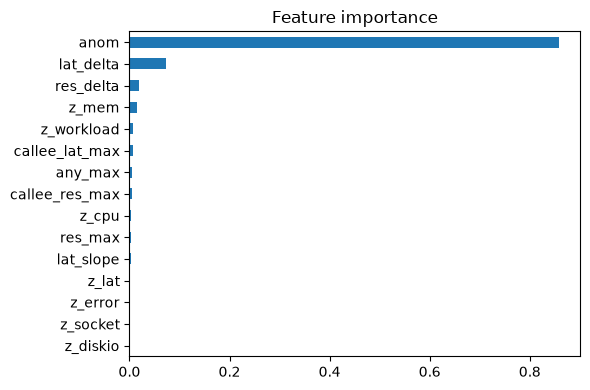

In [36]:
ISO_FEATS = ["z_cpu", "z_mem", "z_diskio", "z_socket", "z_lat", "z_error", "res_max", "any_max"]
CLF_FEATS = ["z_cpu", "z_mem", "z_diskio", "z_socket", "z_workload", "z_error", "z_lat", "lat_slope",
             "res_max", "any_max", "callee_lat_max", "callee_res_max", "lat_delta", "res_delta", "anom"]
tr = feats[~feats.test]
iso = IsolationForest(n_estimators=200, random_state=SEED).fit(tr[tr.t_end < tr.inject][ISO_FEATS])
feats["anom"] = -iso.score_samples(feats[ISO_FEATS])
tr, te = feats[~feats.test], feats[feats.test]
clf = GradientBoostingClassifier(n_estimators=200, max_depth=3, learning_rate=.1, random_state=SEED).fit(tr[CLF_FEATS], tr.y)
feats["risk"] = clf.predict_proba(feats[CLF_FEATS])[:, 1]
te = feats[feats.test]
p, r, f1, _ = precision_recall_fscore_support(te.y, te.risk >= THR, average="binary")
print(f"Row-level (service-bin) test metrics @thr={THR}: precision={p:.2f} recall={r:.2f} f1={f1:.2f}")
pd.Series(clf.feature_importances_, CLF_FEATS).sort_values().plot.barh(title="Feature importance", figsize=(6, 4))
plt.tight_layout(); plt.show()

## 8. Comparison with conventional monitoring
Tests all methods on the 50 unseen test cases using the same alert rule (score at or above the threshold for 3 consecutive batches).

- **CascadeGuard:** model risk at least 0.6.
- **N-sigma monitor:** any metric of any service drifts 6 or more standard deviations from baseline.
- **SLO latency monitor:** frontend latency above 2 times its baseline, a typical user-facing alert.

**Measures:** detection rate, time-to-detect after injection, whether the true source ranks first or in the top three, and false alarms before the fault starts.

**What our run shows**

| | CascadeGuard | N-sigma | SLO latency |
|---|---|---|---|
| Detected | 47/50 | 49/50 | 14/50 |
| False-alarm cases | **2/50** | 18/50 | 3/50 |
| Source correct (top-1) | **47/47** | 39/49 | 7/14 |
| Median time-to-detect | 34 s | 29 s | 31.5 s |

CascadeGuard's advantage is **far fewer false alarms and much better source identification**. It is *not* faster than N-sigma, and it was slower on `loss` faults (59 s versus 29 s). Say this openly.

**Caution:** perfect source accuracy is partly because only 5 services ever carry the fault, and the test cases repeat fault and service combinations seen in training. It does not prove the model would generalise to new faults.

In [37]:
def streak_alerts(mx, thr):
    ok = ((mx >= thr).astype(int).rolling(CONSEC).sum() == CONSEC)
    return list(mx.index[ok.values])

def evaluate(col, thr, src_col=None):
    src_col, out = src_col or col, []
    for cs in cases[cases.test].itertuples():
        d = feats[feats.case == cs.case]
        mx = d.groupby("t_end")[col].max()
        al = streak_alerts(mx[mx.index >= cs.inject], thr)
        rec = dict(case=cs.case, service=cs.service, fault=cs.fault,
                   false_alarm=len(streak_alerts(mx[mx.index < cs.inject], thr)) > 0, detected=bool(al))
        if al:
            t = al[0]; snap = d[d.t_end == t].set_index("service")[src_col].sort_values(ascending=False)
            rec.update(ttd=t - cs.inject, t_alert=t, top1=snap.index[0] == cs.service, top3=cs.service in snap.index[:3])
        out.append(rec)
    return pd.DataFrame(out)

R = {"CascadeGuard": evaluate("risk", THR),
     "N-sigma monitor": evaluate("any_max", NSIGMA_THR),
     "SLO latency monitor": evaluate("fe_lat_ratio", SLO_MULT, src_col="any_max")}

def summ(r):
    d = r[r.detected]
    return pd.Series({"detected": f"{int(r.detected.sum())}/{len(r)}",
                      "median time-to-detect (s)": d.ttd.median(), "mean time-to-detect (s)": round(d.ttd.mean(), 1),
                      "source top-1": f"{int(d.top1.sum())}/{len(d)}", "source top-3": f"{int(d.top3.sum())}/{len(d)}",
                      "false-alarm cases": f"{int(r.false_alarm.sum())}/{len(r)}"})
print(pd.DataFrame({k: summ(v) for k, v in R.items()}).T.to_string())
print("\nMedian time-to-detect by fault type (s):")
print(pd.DataFrame({k: v[v.detected].groupby("fault").ttd.median() for k, v in R.items()}).round(1))
print("\nCascadeGuard source top-1 accuracy by fault type:")
print(R["CascadeGuard"][R["CascadeGuard"].detected].groupby("fault").top1.mean().round(2))

                    detected median time-to-detect (s) mean time-to-detect (s) source top-1 source top-3 false-alarm cases
CascadeGuard           47/50                      34.0                    44.3        47/47        47/47              2/50
N-sigma monitor        49/50                      29.0                    33.0        39/49        46/49             18/50
SLO latency monitor    14/50                      31.5                    94.0         7/14        12/14              3/50

Median time-to-detect by fault type (s):
       CascadeGuard  N-sigma monitor  SLO latency monitor
fault                                                    
cpu            34.0             29.0                  NaN
delay          41.5             44.0                 29.0
disk           34.0             36.5                231.5
loss           59.0             29.0                 29.0
mem            29.0             24.0                  NaN

CascadeGuard source top-1 accuracy by fault type:
fault
cpu

## 9. Impact check: does the predicted spread match reality?
For each correct detection, the call graph predicts which callers are at risk. This cell compares that prediction with the services whose latency actually rose (3 or more standard deviations) within 2 minutes of the alert.

- **Precision** is the share of predicted services that really degraded. **Recall** is the share of degraded services that were predicted.
- **Our run:** precision 0.57 and recall 0.47. The call graph captures roughly half of the real spread, so describe the impact estimate as an approximate guide, not an exact forecast.

In [38]:
rows = []
cm = R["CascadeGuard"]; cm = cm[cm.detected & cm.top1]
for rec in cm.itertuples():
    d = feats[feats.case == rec.case]
    has_lat = {s for s, g in d.groupby("service") if g.z_lat.abs().sum() > 0} - {rec.service}
    win = d[(d.t_end >= rec.t_alert) & (d.t_end <= rec.t_alert + 120)]
    actual = {s for s, g in win.groupby("service") if s in has_lat and g.z_lat.max() >= 3}
    pred = set(IMPACTED[rec.service]) & has_lat
    hit = len(pred & actual)
    rows.append(dict(case=rec.case, pred=len(pred), actual=len(actual), hit=hit,
                     precision=hit / len(pred) if pred else np.nan, recall=hit / len(actual) if actual else np.nan))
imp = pd.DataFrame(rows)
print(f"{len(imp)} correctly-sourced test detections | mean precision {imp.precision.mean():.2f} | mean recall {imp.recall.mean():.2f}")
print("(Precision/recall of the call-graph impact set vs services whose latency actually rose; NaN cases excluded.)")

47 correctly-sourced test detections | mean precision 0.57 | mean recall 0.47
(Precision/recall of the call-graph impact set vs services whose latency actually rose; NaN cases excluded.)


## 10. Explainable alert and streaming replay
- **`alert_card`** builds the operator message: the suspected source and risk, the strongest evidence (metrics and how far from baseline), the callers at risk, whether the payment path is affected, a suggested action, and a confidence level. It only recommends; it never changes any system.
- **`replay`** feeds one case through the models one 5 s batch at a time, like a live stream, and times each batch.

**Example output:** for an `adservice` CPU fault, an alert is raised 29 s after injection with risk 1.00, evidence "cpu +30 sigma", and the frontend flagged as at risk. Scoring takes about **12 ms per batch on LinuxONE**, far below the 5 s window, so the system can keep up with live data.

In [39]:
ACTIONS = {"cpu": "check CPU saturation / autoscaling limits", "mem": "check memory leak or limits",
           "diskio": "check disk I/O pressure", "socket": "check connection/socket exhaustion",
           "lat": "check network delay or slow dependency", "error": "check error spikes in logs"}
def alert_card(b, t, inject):
    top = b.sort_values("risk", ascending=False).iloc[0]; s = top.service
    zs = {k: top["z_" + k] for k in ["cpu", "mem", "diskio", "socket", "lat", "error"] if abs(top["z_" + k]) >= 3}
    ev = sorted(zs.items(), key=lambda kv: -abs(kv[1]))[:3]
    conf = "High" if top.risk > .85 else "Moderate" if top.risk > .7 else "Low-moderate"
    imp_ = IMPACTED[s]; pay = bool(PAYMENT_PATH & ({s} | set(imp_)))
    print(f"EARLY WARNING  (t = injection + {t - inject}s)")
    print(f"  Suspected source : {s}  (risk {top.risk:.2f})")
    print(f"  Evidence         : " + (", ".join(f"{k} {v:+.1f} sigma vs baseline" for k, v in ev) or "multiple weak signals"))
    print(f"  Callers at risk  : {', '.join(imp_) if imp_ else 'none'}")
    print(f"  Payment flow     : {'AFFECTED / at risk' if pay else 'not on the call path'}")
    print(f"  Suggested action : investigate {s}; " + "; ".join(ACTIONS[k] for k, _ in ev[:2]) + " (operator-approved runbook only)")
    print(f"  Confidence       : {conf}")
    return top

def replay(case, verbose=True):
    d = feats[feats.case == case]; cs = cases[cases.case == case].iloc[0]
    streak, alert, times = 0, None, []
    for t in sorted(d[d.t_end >= cs.inject - 60].t_end.unique()):
        bt = d[d.t_end == t].copy(); t0 = time.perf_counter()
        bt["anom"] = -iso.score_samples(bt[ISO_FEATS]); bt["risk"] = clf.predict_proba(bt[CLF_FEATS])[:, 1]
        times.append((time.perf_counter() - t0) * 1000)
        streak = streak + 1 if (bt.risk.max() >= THR and t >= cs.inject) else 0
        if streak >= CONSEC and alert is None: alert = (t, bt)
    if verbose:
        print(f"Case {case}: true source={cs.service}, fault={cs.fault}")
        if alert: alert_card(alert[1], alert[0], cs.inject)
        else: print("No alert fired.")
        print(f"Scoring time per {BIN}s batch: mean {np.mean(times):.1f} ms, max {np.max(times):.1f} ms")
    return alert, cs

demo = R["CascadeGuard"]; demo = demo[demo.detected & demo.top1].case.iloc[0]
alert, cs = replay(demo)

Case data/RE1/RE1-OB/adservice_cpu/4: true source=adservice, fault=cpu
EARLY WARNING  (t = injection + 29.0s)
  Suspected source : adservice  (risk 1.00)
  Evidence         : cpu +30.0 sigma vs baseline
  Callers at risk  : frontend
  Payment flow     : not on the call path
  Suggested action : investigate adservice; check CPU saturation / autoscaling limits (operator-approved runbook only)
  Confidence       : High
Scoring time per 5s batch: mean 12.0 ms, max 13.4 ms


## 11. Charts for the presentation
- **`plot_case`** draws two panels for one case. The top shows model risk per service (the thick line is the true root cause), with the injection time dashed and the CascadeGuard alert in green. The bottom shows the N-sigma view with its alert in orange.
- **`plot_graph`** draws the Online Boutique call graph at alert time. Colour shows risk and the red outline marks the suspected source.

Save these two charts and add them to the slides.

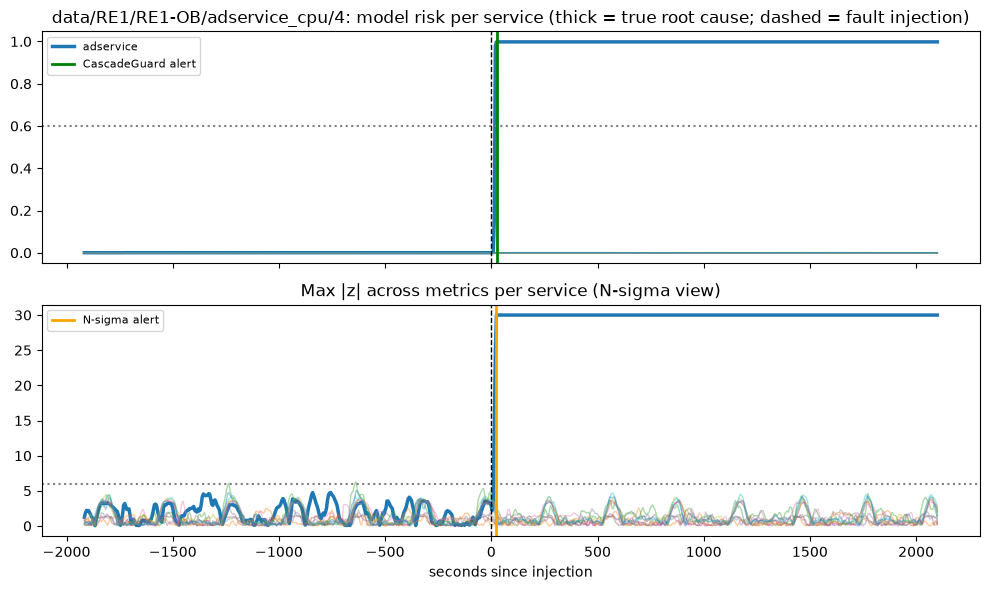

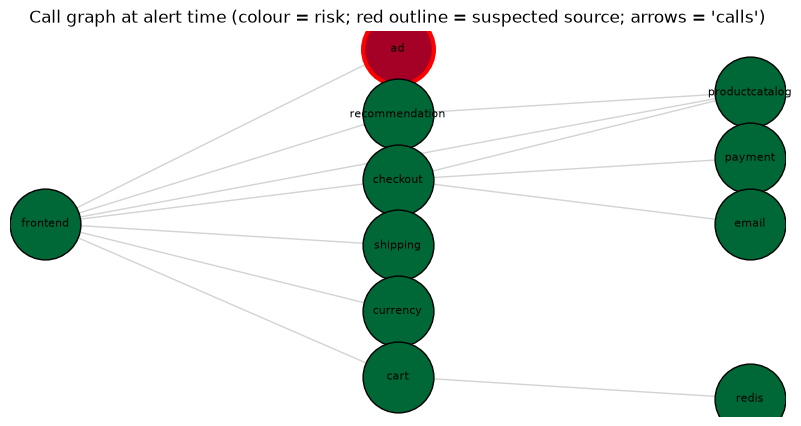

In [40]:
def plot_case(case):
    d = feats[feats.case == case]; cs = cases[cases.case == case].iloc[0]
    fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
    for s in SERVICES:
        g = d[d.service == s]; hl = s == cs.service
        ax[0].plot(g.t_end - cs.inject, g.risk, lw=2.5 if hl else 1, alpha=1 if hl else .5, label=s if hl else None)
        ax[1].plot(g.t_end - cs.inject, g.any_max.clip(upper=30), lw=2.5 if hl else 1, alpha=1 if hl else .4)
    ax[0].axhline(THR, ls=":", c="gray"); ax[1].axhline(NSIGMA_THR, ls=":", c="gray")
    for a in ax: a.axvline(0, c="k", ls="--", lw=1)
    for name, c, a in [("CascadeGuard", "green", ax[0]), ("N-sigma", "orange", ax[1])]:
        r_ = R[name if name != "N-sigma" else "N-sigma monitor"]; r_ = r_[r_.case == case]
        if len(r_) and r_.detected.iloc[0]: a.axvline(r_.t_alert.iloc[0] - cs.inject, c=c, lw=2, label=f"{name} alert")
    ax[0].set_title(f"{case}: model risk per service (thick = true root cause; dashed = fault injection)")
    ax[1].set_title("Max |z| across metrics per service (N-sigma view)"); ax[1].set_xlabel("seconds since injection")
    ax[0].legend(fontsize=8); ax[1].legend(fontsize=8); plt.tight_layout(); plt.show()
plot_case(demo)

POS = {"frontend": (0, 4), "adservice": (1, 8), "recommendationservice": (1, 6.5), "checkoutservice": (1, 5),
       "shippingservice": (1, 3.5), "currencyservice": (1, 2), "cartservice": (1, 0.5), "productcatalogservice": (2, 7),
       "paymentservice": (2, 5.5), "emailservice": (2, 4), "redis": (2, 0)}
def plot_graph(b, source):
    fig, ax = plt.subplots(figsize=(10, 5)); cmap = plt.get_cmap("RdYlGn_r"); rk = b.set_index("service").risk
    for a, v in CALLS.items():
        for c in v: ax.annotate("", xy=POS[c], xytext=POS[a], arrowprops=dict(arrowstyle="->", color="lightgray"))
    for s, (x, y) in POS.items():
        ax.scatter(x, y, s=2600, c=[cmap(float(rk.get(s, 0)))], edgecolor="red" if s == source else "k", linewidths=3 if s == source else 1, zorder=3)
        ax.text(x, y, s.replace("service", ""), ha="center", va="center", fontsize=8, zorder=4)
    ax.set_title("Call graph at alert time (colour = risk; red outline = suspected source; arrows = 'calls')"); ax.axis("off"); plt.show()
if alert: plot_graph(alert[1], alert[1].sort_values("risk").iloc[-1].service)

## Summary and limitations
**What the results show:** on 50 unseen real fault-injection cases, CascadeGuard detected 47, with only 2 false-alarm cases (N-sigma had 18), and named the right source service in all 47 detections. Scoring runs at about 12 ms per 5 s batch on IBM LinuxONE.

**Limitations to state openly**
- Lab fault injection on one demo application, not production bank traffic.
- Faults start at a known moment, so this measures detection speed, not forecasting.
- Not faster than a plain N-sigma monitor, and slower on `loss` faults.
- The impact estimate matches about half of the real spread (precision 0.57, recall 0.47).
- Test cases repeat the same fault and service combinations as training.

**Next steps:** hold out an entire fault type (leave-one-fault-out), add a baseline that ignores the metrics, repeat with several random splits, and map the `latency` and `load` column names that are currently unused.